In [1]:
# Install Kaggle API
!pip install kaggle

# Install additional libraries if not already available
!pip install tensorflow==2.12.0
!pip install opencv-python
!pip install scikit-learn
!pip install matplotlib


INFO: pip is looking at multiple versions of jax to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 585.9/585.9 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 77.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 102.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 440.7/440.7 kB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.9/77.9 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.6/79.6 MB 8.5 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 1.16.0
    Uninstalling wrapt-1.16.0:
      Successfully uninstalled wrapt-1.16.0
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    U

In [1]:
import os
import json

# Create the .kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Move the kaggle.json file to the .kaggle directory
!cp kaggle.json /root/.kaggle/

# Set the permissions to read/write for the user only
os.chmod('/root/.kaggle/kaggle.json', 0o600)


In [2]:
# Test Kaggle API
!kaggle datasets list | head -n 5


ref                                                          title                                           size  lastUpdated          downloadCount  voteCount  usabilityRating  
-----------------------------------------------------------  ---------------------------------------------  -----  -------------------  -------------  ---------  ---------------  
valakhorasani/mobile-device-usage-and-user-behavior-dataset  Mobile Device Usage and User Behavior Dataset   11KB  2024-09-28 20:21:12          15938        349  1.0              
abdullah0a/comprehensive-weight-change-prediction            Diet Analysis , Predict The Weight               3KB  2024-10-27 17:43:55            998         26  1.0              
valakhorasani/gym-members-exercise-dataset                   Gym Members Exercise Dataset                    22KB  2024-10-06 11:27:38           8723        144  1.0              


In [8]:
from kaggle.api.kaggle_api_extended import KaggleApi

# Initialize Kaggle API
api = KaggleApi()
api.authenticate()

# Define dataset details
dataset_owner = 'navoneel'
dataset_name = 'brain-mri-images-for-brain-tumor-detection'

# Download the dataset
api.dataset_download_files(f'{dataset_owner}/{dataset_name}', path='data/', unzip=True)
!kaggle datasets download -d navoneel/brain-mri-images-for-brain-tumor-detection -p /content --unzip



Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
License(s): copyright-authors
 79% 12.0M/15.1M [00:00<00:00, 21.1MB/s]
100% 15.1M/15.1M [00:00<00:00, 16.1MB/s]


In [10]:
import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
import tensorflow as tf

# Define image properties
IMAGE_HEIGHT, IMAGE_WIDTH = 128, 128  # Adjust as needed
IMAGE_CHANNELS = 1  # Grayscale images

# Paths to images and masks
IMAGE_DIR = '/content/brain_tumor_dataset/yes'  # Adjust based on dataset structure
MASK_DIR = '/content/yes'  # Adjust based on dataset structure

def load_data(image_dir, mask_dir, img_size=(IMAGE_HEIGHT, IMAGE_WIDTH)):
    images = []
    masks = []
    image_files = os.listdir(image_dir)
    mask_files = os.listdir(mask_dir)

    for img_name in image_files:
        # Load and preprocess the image
        img_path = os.path.join(image_dir, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue  # Skip if image is not readable
        img = cv2.resize(img, img_size)
        img = img / 255.0  # Normalize
        images.append(img[..., np.newaxis])

        # Load and preprocess the mask
        mask_path = os.path.join(mask_dir, img_name)
        if os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, img_size)
            mask = mask / 255.0  # Normalize
            mask = (mask > 0.5).astype(np.float32)  # Binarize
            masks.append(mask[..., np.newaxis])
        else:
            # If mask not available, use zeros
            masks.append(np.zeros((img_size[0], img_size[1], 1), dtype=np.float32))

    return np.array(images), np.array(masks)

# Load images and masks
X, y = load_data(IMAGE_DIR, MASK_DIR)

print(f'Images shape: {X.shape}')
print(f'Masks shape: {y.shape}')


Images shape: (155, 128, 128, 1)
Masks shape: (155, 128, 128, 1)


In [11]:
# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set: {X_train.shape}, {y_train.shape}')
print(f'Validation set: {X_val.shape}, {y_val.shape}')


Training set: (124, 128, 128, 1), (124, 128, 128, 1)
Validation set: (31, 128, 128, 1), (31, 128, 128, 1)


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define data augmentation parameters
data_gen_args = dict(
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Create ImageDataGenerators
image_datagen = ImageDataGenerator(**data_gen_args)
mask_datagen = ImageDataGenerator(**data_gen_args)

# Fit the generators (if using featurewise normalization)
image_datagen.fit(X_train, augment=True, seed=42)
mask_datagen.fit(y_train, augment=True, seed=42)

# Create a generator that combines images and masks
def train_generator(image_gen, mask_gen, images, masks, batch_size):
    image_generator = image_gen.flow(images, batch_size=batch_size, seed=42)
    mask_generator = mask_gen.flow(masks, batch_size=batch_size, seed=42)
    while True:
        img = next(image_generator)
        mask = next(mask_generator)
        yield img, mask

batch_size = 16
train_gen = train_generator(image_datagen, mask_datagen, X_train, y_train, batch_size)
steps_per_epoch = len(X_train) // batch_size


In [13]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, UpSampling2D, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def unet_model(input_size=(IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS)):
    inputs = Input(input_size)

    # Downsampling
    conv1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    conv1 = Conv2D(64, 3, activation='relu', padding='same')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)

    conv2 = Conv2D(128, 3, activation='relu', padding='same')(pool1)
    conv2 = Conv2D(128, 3, activation='relu', padding='same')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)

    conv3 = Conv2D(256, 3, activation='relu', padding='same')(pool2)
    conv3 = Conv2D(256, 3, activation='relu', padding='same')(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)

    conv4 = Conv2D(512, 3, activation='relu', padding='same')(pool3)
    conv4 = Conv2D(512, 3, activation='relu', padding='same')(conv4)
    drop4 = Dropout(0.5)(conv4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(drop4)

    # Bottleneck
    conv5 = Conv2D(1024, 3, activation='relu', padding='same')(pool4)
    conv5 = Conv2D(1024, 3, activation='relu', padding='same')(conv5)
    drop5 = Dropout(0.5)(conv5)

    # Upsampling
    up6 = UpSampling2D(size=(2, 2))(drop5)
    up6 = Conv2D(512, 2, activation='relu', padding='same')(up6)
    merge6 = concatenate([drop4, up6], axis=3)
    conv6 = Conv2D(512, 3, activation='relu', padding='same')(merge6)
    conv6 = Conv2D(512, 3, activation='relu', padding='same')(conv6)

    up7 = UpSampling2D(size=(2, 2))(conv6)
    up7 = Conv2D(256, 2, activation='relu', padding='same')(up7)
    merge7 = concatenate([conv3, up7], axis=3)
    conv7 = Conv2D(256, 3, activation='relu', padding='same')(merge7)
    conv7 = Conv2D(256, 3, activation='relu', padding='same')(conv7)

    up8 = UpSampling2D(size=(2, 2))(conv7)
    up8 = Conv2D(128, 2, activation='relu', padding='same')(up8)
    merge8 = concatenate([conv2, up8], axis=3)
    conv8 = Conv2D(128, 3, activation='relu', padding='same')(merge8)
    conv8 = Conv2D(128, 3, activation='relu', padding='same')(conv8)

    up9 = UpSampling2D(size=(2, 2))(conv8)
    up9 = Conv2D(64, 2, activation='relu', padding='same')(up9)
    merge9 = concatenate([conv1, up9], axis=3)
    conv9 = Conv2D(64, 3, activation='relu', padding='same')(merge9)
    conv9 = Conv2D(64, 3, activation='relu', padding='same')(conv9)
    conv9 = Conv2D(2, 3, activation='relu', padding='same')(conv9)

    conv10 = Conv2D(1, 1, activation='sigmoid')(conv9)

    model = Model(inputs=inputs, outputs=conv10)

    return model

# Instantiate the model
model = unet_model()

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

# Display the model architecture
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 128, 128, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 128, 128, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 128, 128, 64  36928       ['conv2d[0][0]']                 
                                )                                                             

In [15]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Define callbacks
checkpoint = ModelCheckpoint(
    'unet_brain_tumor.h5',
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)
earlystop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

callbacks_list = [checkpoint, earlystop, reduce_lr]

# Train the model
epochs = 20

history = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=callbacks_list
)


Epoch 1/20
7/7 [==============================] - ETA: 0s - loss: 0.6929 - accuracy: 0.7704 
Epoch 1: val_loss improved from inf to 0.69277, saving model to unet_brain_tumor.h5
7/7 [==============================] - 180s 26s/step - loss: 0.6929 - accuracy: 0.7704 - val_loss: 0.6928 - val_accuracy: 0.8163 - lr: 1.0000e-04
Epoch 2/20
7/7 [==============================] - ETA: 0s - loss: 0.6926 - accuracy: 0.7773 
Epoch 2: val_loss improved from 0.69277 to 0.69255, saving model to unet_brain_tumor.h5
7/7 [==============================] - 172s 25s/step - loss: 0.6926 - accuracy: 0.7773 - val_loss: 0.6925 - val_accuracy: 0.8167 - lr: 1.0000e-04
Epoch 3/20
7/7 [==============================] - ETA: 0s - loss: 0.6924 - accuracy: 0.7823 
Epoch 3: val_loss improved from 0.69255 to 0.69233, saving model to unet_brain_tumor.h5
7/7 [==============================] - 174s 25s/step - loss: 0.6924 - accuracy: 0.7823 - val_loss: 0.6923 - val_accuracy: 0.8168 - lr: 1.0000e-04
Epoch 4/20
7/7 [=======

1/1 [==============================] - 11s 11s/step - loss: 0.6479 - accuracy: 0.8433
Validation Loss: 0.6479461193084717
Validation Accuracy: 0.8432794213294983


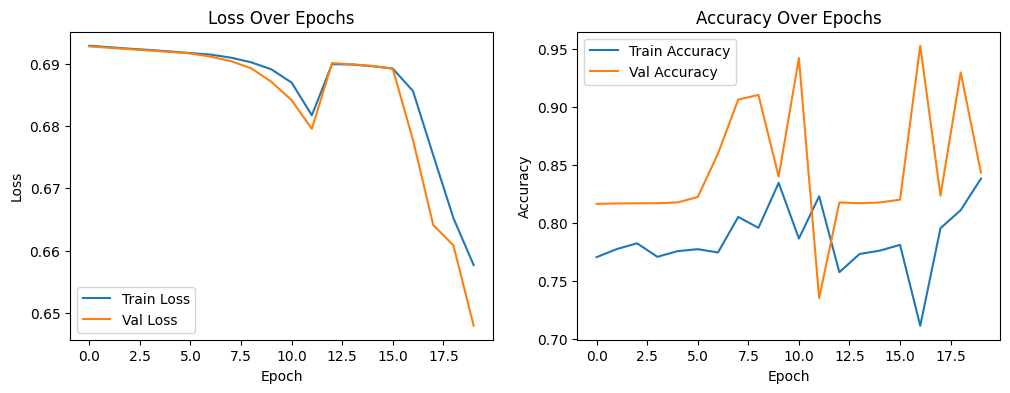

In [16]:
import matplotlib.pyplot as plt

# Load the best model
model.load_weights('unet_brain_tumor.h5')

# Evaluate on validation data
loss, accuracy = model.evaluate(X_val, y_val)
print(f'Validation Loss: {loss}')
print(f'Validation Accuracy: {accuracy}')

# Plot training & validation loss values
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot training & validation accuracy values
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()


1/1 [==============================] - 1s 519ms/step


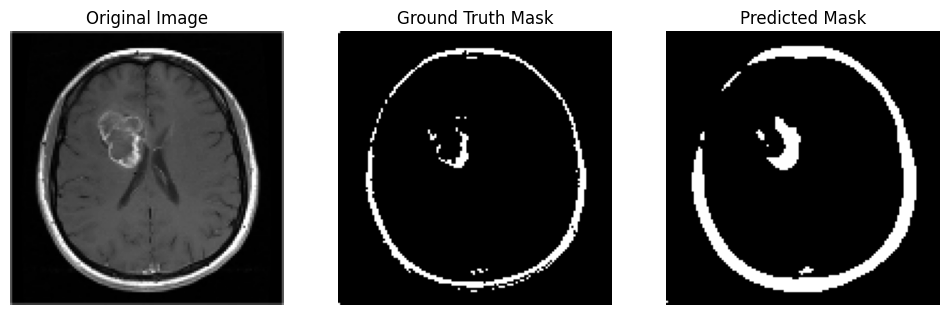

In [17]:
def predict_and_display(model, image, mask=None):
    # Predict the mask
    pred_mask = model.predict(image[np.newaxis, ...])[0]
    pred_mask = (pred_mask > 0.5).astype(np.uint8)

    plt.figure(figsize=(12, 6))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    # Ground Truth Mask
    if mask is not None:
        plt.subplot(1, 3, 2)
        plt.imshow(mask.squeeze(), cmap='gray')
        plt.title('Ground Truth Mask')
        plt.axis('off')

    # Predicted Mask
    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap='gray')
    plt.title('Predicted Mask')
    plt.axis('off')

    plt.show()

# Example usage with a validation image
idx = 0  # Change index as needed
predict_and_display(model, X_val[idx], y_val[idx])


1/1 [==============================] - 0s 310ms/step


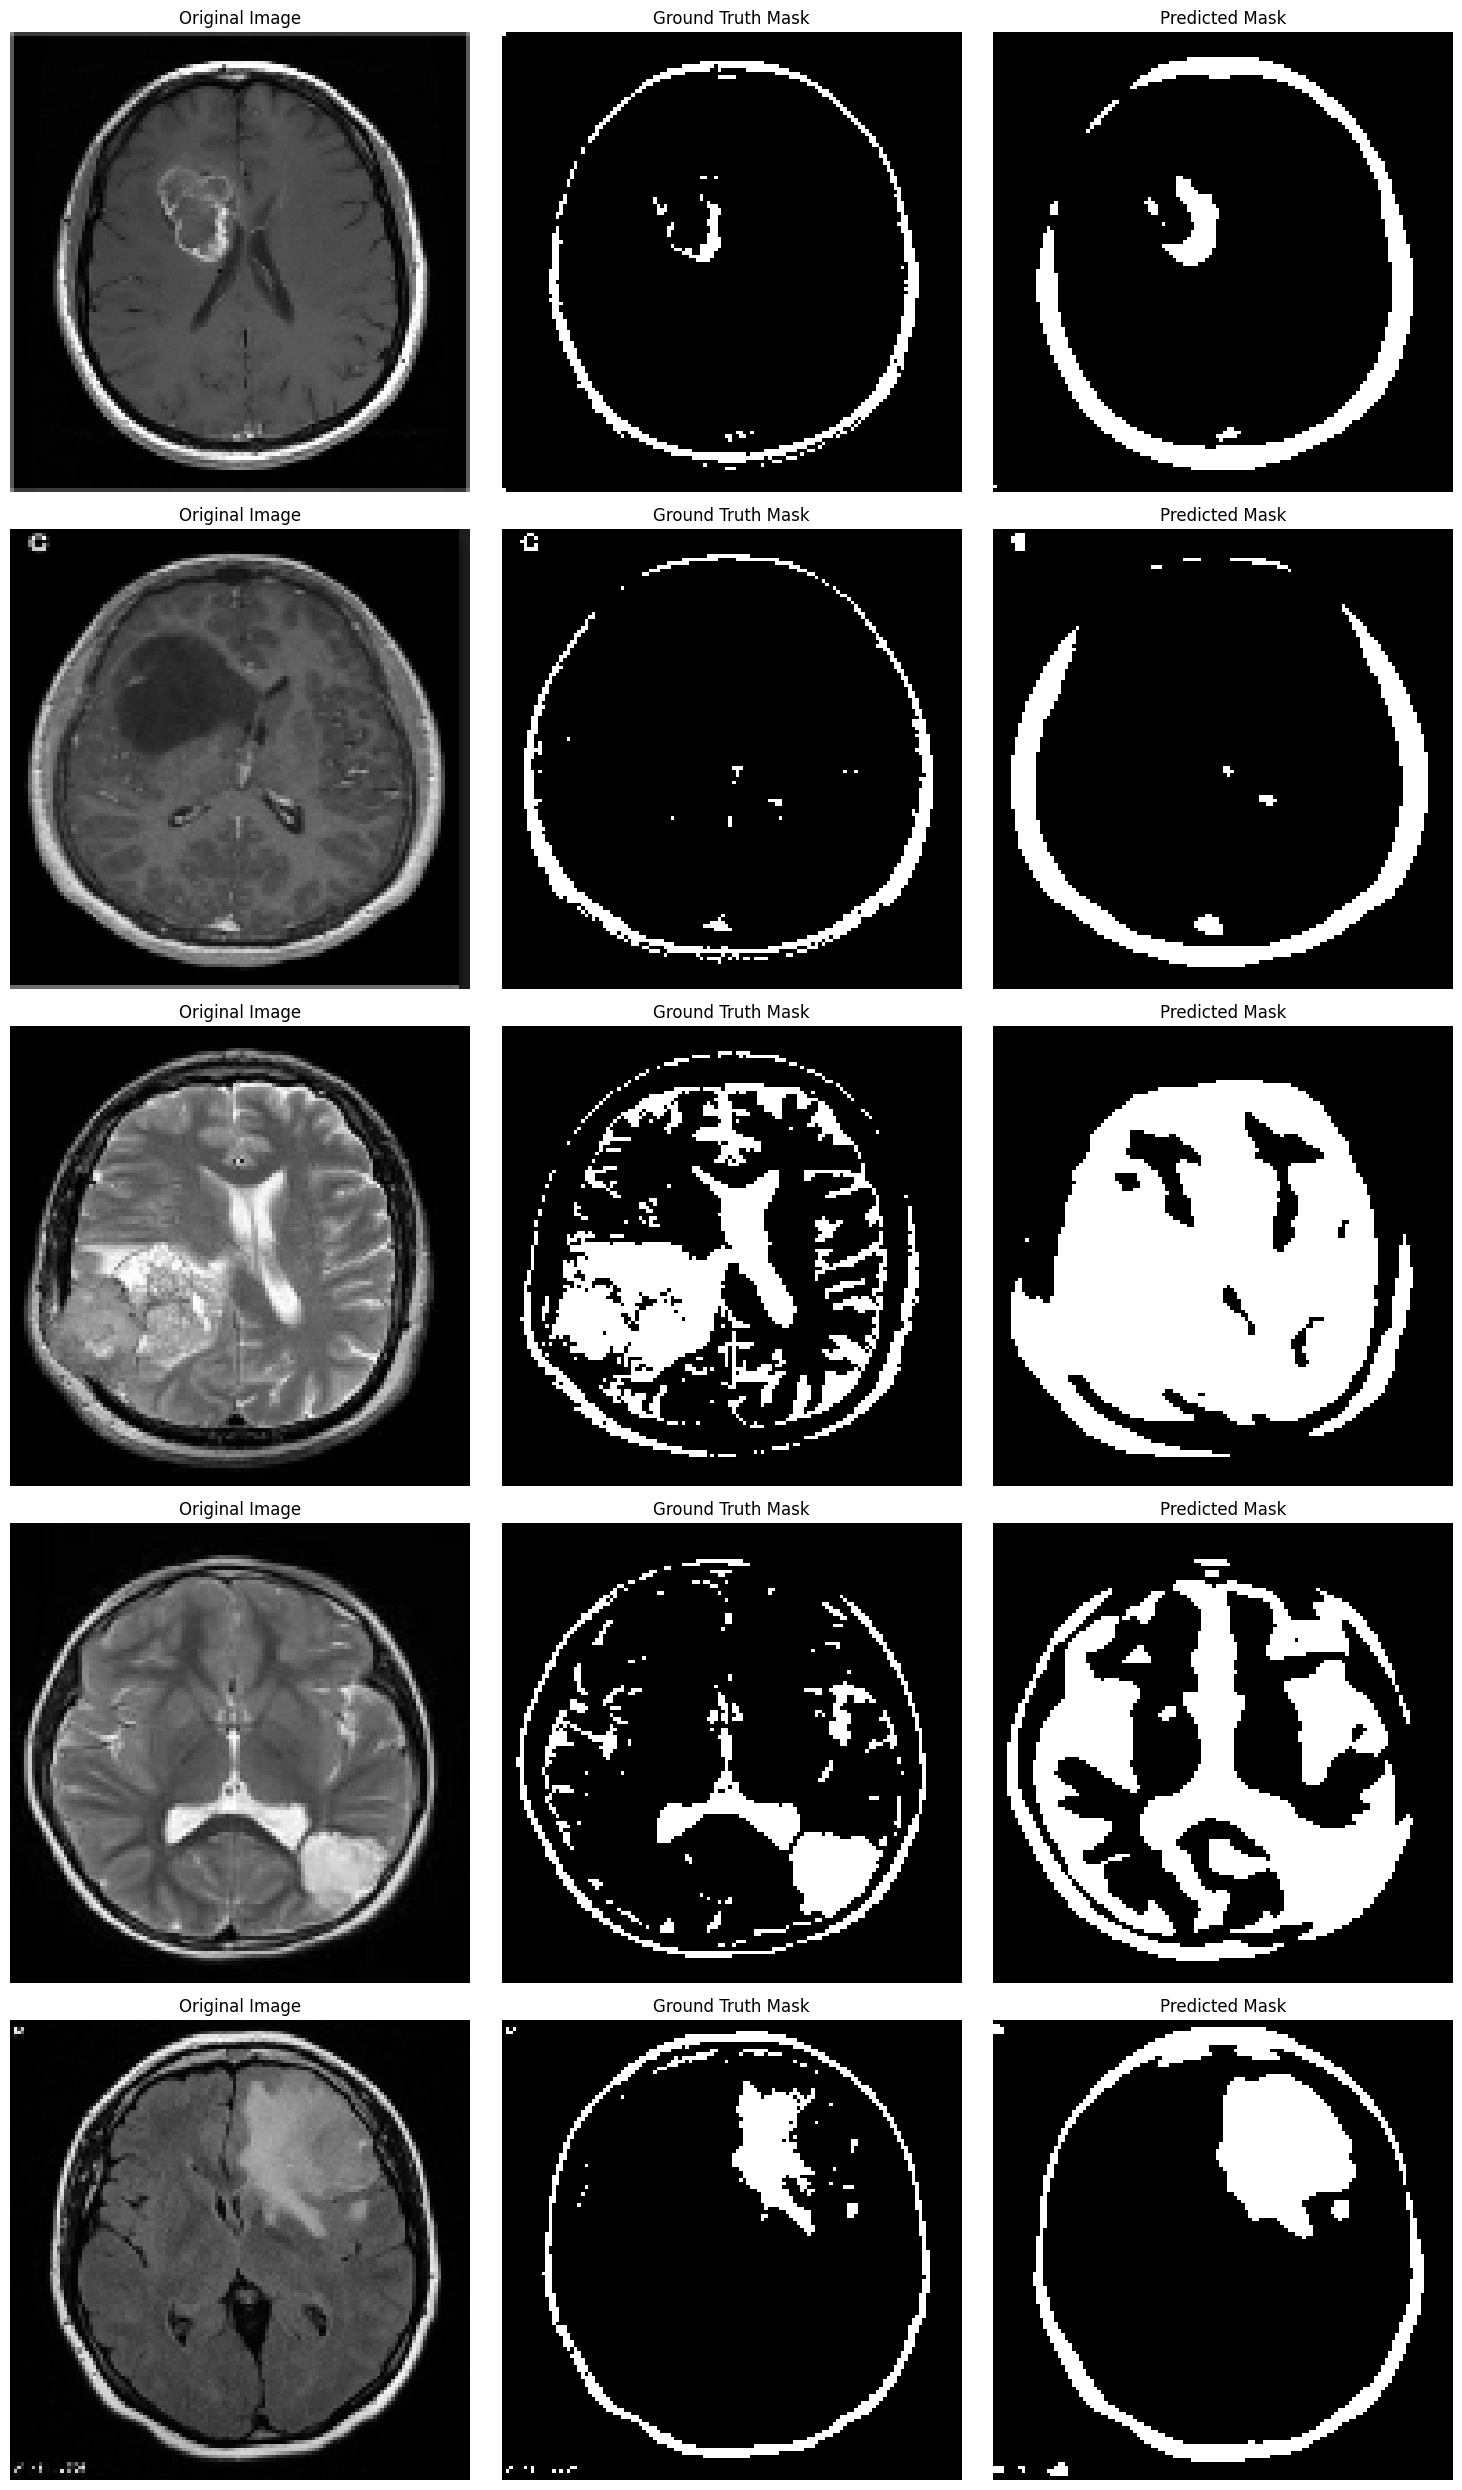

In [18]:
def visualize_predictions(model, images, masks, num=5):
    plt.figure(figsize=(15, num * 5))
    for i in range(num):
        image = images[i]
        mask = masks[i]
        pred_mask = model.predict(image[np.newaxis, ...])[0]
        pred_mask = (pred_mask > 0.5).astype(np.uint8)

        # Original Image
        plt.subplot(num, 3, 3*i + 1)
        plt.imshow(image.squeeze(), cmap='gray')
        plt.title('Original Image')
        plt.axis('off')

        # Ground Truth Mask
        plt.subplot(num, 3, 3*i + 2)
        plt.imshow(mask.squeeze(), cmap='gray')
        plt.title('Ground Truth Mask')
        plt.axis('off')

        # Predicted Mask
        plt.subplot(num, 3, 3*i + 3)
        plt.imshow(pred_mask.squeeze(), cmap='gray')
        plt.title('Predicted Mask')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Visualize first 5 predictions
visualize_predictions(model, X_val, y_val, num=5)
